In [1]:
# ============================================================
# 05_transfer_learning_classifier_v2 - Cell 1
# Imports, seed, dataset_final ke train/val/test CSVs load
# ============================================================

# PyTorch, neural network aur optimizer modules
import torch
import torch.nn as nn
import torch.optim as optim

# Pretrained models (ResNet18) ke liye torchvision
from torchvision import models

# Dataset/DataLoader (cached features ke batches ke liye)
from torch.utils.data import TensorDataset, DataLoader

# Images open karne ke liye PIL
from PIL import Image

# Pandas, NumPy, os, time, random
import pandas as pd
import numpy as np
import os
import time
import random

# Matplotlib graphs ke liye
import matplotlib.pyplot as plt

# Metrics
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

# Seed fix karta hai taaki results repeat ho sakein
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Laptop CPU-only hai
device = torch.device("cpu")

# Paths (dataset_final)
PROJECT_DIR = r"C:\Projects\Internship_Learning"
DATASET_DIR = os.path.join(PROJECT_DIR, "dataset_final")
IMAGES_DIR = os.path.join(DATASET_DIR, "images")

# Pehle se bane split CSVs load karta hai (train_test_split use NAHI kar rahe)
train_df = pd.read_csv(os.path.join(DATASET_DIR, "train.csv"))
val_df = pd.read_csv(os.path.join(DATASET_DIR, "val.csv"))
test_df = pd.read_csv(os.path.join(DATASET_DIR, "test.csv"))

# Label mapping (purane jaisa) aur class names
label_map = {"good": 0, "average": 1, "poor": 2}
CLASS_NAMES = ["good", "average", "poor"]

# Sizes aur class distribution print karta hai
print("PyTorch version:", torch.__version__)
print("Train:", len(train_df), "| Val:", len(val_df), "| Test:", len(test_df))
for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(name, d["label"].value_counts().to_dict())

# Overlap check (teeno 0 hone chahiye)
tr, va, te = set(train_df["filename"]), set(val_df["filename"]), set(test_df["filename"])
print("Overlap train-val:", len(tr & va), "| train-test:", len(tr & te), "| val-test:", len(va & te))

# Missing images check (0 hona chahiye)
missing = [f for f in (tr | va | te) if not os.path.exists(os.path.join(IMAGES_DIR, f))]
print("Missing images:", len(missing))

PyTorch version: 2.12.1+cpu
Train: 685 | Val: 147 | Test: 147
train {'average': 275, 'good': 223, 'poor': 187}
val {'average': 59, 'good': 48, 'poor': 40}
test {'average': 59, 'good': 48, 'poor': 40}
Overlap train-val: 0 | train-test: 0 | val-test: 0
Missing images: 0


In [2]:
# ============================================================
# 05_transfer_learning_classifier_v2 - Cell 2
# Pretrained ResNet18 (frozen, eval mode) se saari images ke 512-d features nikalna aur cache karna
# ============================================================

# ImageNet normalization ke mean/std (purane notebook jaisa)
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

# Pretrained ResNet18 load karta hai (ImageNet weights, purane jaisa)
backbone = models.resnet18(weights="IMAGENET1K_V1")

# Final classification layer hata ke Identity laga deta hai, taaki output 512-d feature vector aaye
backbone.fc = nn.Identity()

# Sabhi parameters freeze karta hai (training nahi hogi)
for p in backbone.parameters():
    p.requires_grad = False

# Eval mode: BatchNorm stats fix rahenge (frozen backbone ke liye sahi)
backbone.eval()

# Ek split ke liye features nikalne ka function
def extract_resnet_features(df, split_name, batch_size=32):

    # Start time
    t0 = time.time()

    # Filenames list
    files = df["filename"].tolist()

    # Saare batches ke features yahan jama honge
    feats = []

    # Batches me process karta hai
    for start in range(0, len(files), batch_size):

        # Is batch ki images load karke tensor me convert karta hai
        batch = []
        for fname in files[start:start + batch_size]:

            # Image open karke RGB, 224x224 resize (purane jaisa)
            img = Image.open(os.path.join(IMAGES_DIR, fname)).convert("RGB")
            img = img.resize((224, 224), Image.BILINEAR)

            # uint8 array -> float tensor (3, 224, 224), 0-1 range, phir normalize
            t = torch.from_numpy(np.asarray(img, dtype=np.uint8)).permute(2, 0, 1).float() / 255.0
            t = (t - MEAN) / STD
            batch.append(t)

        # Batch tensor (B, 3, 224, 224)
        xb = torch.stack(batch)

        # Gradient ke bina forward pass, 512-d features
        with torch.no_grad():
            feats.append(backbone(xb))

    # Saare batches ko jodta hai (N, 512)
    feats = torch.cat(feats)
    print(f"{split_name}: {tuple(feats.shape)} in {time.time() - t0:.1f} sec")
    return feats

# Teeno splits ke features
train_feats = extract_resnet_features(train_df, "train")
val_feats = extract_resnet_features(val_df, "val")
test_feats = extract_resnet_features(test_df, "test")

# Labels ko numeric tensor me convert karta hai (.tolist() se Arrow string issue nahi aata)
train_labels = torch.tensor([label_map[l] for l in train_df["label"].tolist()])
val_labels = torch.tensor([label_map[l] for l in val_df["label"].tolist()])
test_labels = torch.tensor([label_map[l] for l in test_df["label"].tolist()])

# Features ko disk pe save karta hai (kernel restart ho to dobara na nikalna pade)
FEAT_PATH = os.path.join(DATASET_DIR, "resnet18_features.npz")
np.savez(
    FEAT_PATH,
    train=train_feats.numpy(), val=val_feats.numpy(), test=test_feats.numpy(),
    train_labels=train_labels.numpy(), val_labels=val_labels.numpy(), test_labels=test_labels.numpy(),
)
print("Saved:", FEAT_PATH)

# Sanity check: features me NaN nahi hone chahiye aur values reasonable range me hon
print("NaN in train feats:", bool(torch.isnan(train_feats).any()))
print("Feature mean/std:", round(train_feats.mean().item(), 3), round(train_feats.std().item(), 3))

C:\Users\ASUS\AppData\Local\Temp\ipykernel_25280\3553610288.py:47: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  t = torch.from_numpy(np.asarray(img, dtype=np.uint8)).permute(2, 0, 1).float() / 255.0


train: (685, 512) in 28.4 sec
val: (147, 512) in 6.3 sec
test: (147, 512) in 5.8 sec
Saved: C:\Projects\Internship_Learning\dataset_final\resnet18_features.npz
NaN in train feats: False
Feature mean/std: 0.813 0.833


In [3]:
# ============================================================
# 05_transfer_learning_classifier_v2 - Cell 3
# Final fc layer (512 -> 3) ko cached features pe train karna; VAL pe best checkpoint
# ============================================================

# Seed dobara set karta hai (fc ke weights init repeatable ho)
torch.manual_seed(SEED)

# Final classification layer: 512 features -> 3 classes (purane notebook jaisa)
fc = nn.Linear(512, 3)

# Cached features ke DataLoaders (batch_size=8, sirf train shuffle)
g = torch.Generator()
g.manual_seed(SEED)
train_loader = DataLoader(TensorDataset(train_feats, train_labels), batch_size=8, shuffle=True, generator=g)
val_loader = DataLoader(TensorDataset(val_feats, val_labels), batch_size=8, shuffle=False)
test_loader = DataLoader(TensorDataset(test_feats, test_labels), batch_size=8, shuffle=False)

# Class weights (train counts ke inverse), 04 v2 jaisa
train_counts = np.bincount(train_labels.numpy(), minlength=3)
class_weights = torch.tensor(len(train_labels) / (3 * train_counts), dtype=torch.float32)
criterion = nn.CrossEntropyLoss(weight=class_weights)

# Adam optimizer, sirf fc ke parameters (lr=0.001 purane jaisa)
optimizer = optim.Adam(fc.parameters(), lr=0.001)

# Checkpoint save ka path
MODEL_DIR = os.path.join(PROJECT_DIR, "model")
os.makedirs(MODEL_DIR, exist_ok=True)
BEST_PATH = os.path.join(MODEL_DIR, "resnet18_fc_v2_best.pth")

# Kisi bhi loader pe evaluate karne ka function: loss, acc, macro F1, preds, labels
def evaluate(loader):
    fc.eval()
    total_loss, preds_all, labels_all = 0.0, [], []
    with torch.no_grad():
        for xb, yb in loader:
            out = fc(xb)
            total_loss += criterion(out, yb).item() * yb.size(0)
            preds_all.extend(out.argmax(dim=1).tolist())
            labels_all.extend(yb.tolist())
    avg_loss = total_loss / len(labels_all)
    acc = accuracy_score(labels_all, preds_all) * 100
    f1 = f1_score(labels_all, preds_all, average="macro") * 100
    return avg_loss, acc, f1, preds_all, labels_all

# Training settings (purane jaisa 15 epochs)
EPOCHS = 15
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "val_f1": []}
best_val_f1, best_epoch = -1.0, 0

print("Training started...")
print("=" * 70)

for epoch in range(1, EPOCHS + 1):

    # Training mode
    fc.train()
    running_loss, correct, total = 0.0, 0, 0

    # Batch-wise training
    for xb, yb in train_loader:
        out = fc(xb)
        loss = criterion(out, yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * yb.size(0)
        correct += (out.argmax(dim=1) == yb).sum().item()
        total += yb.size(0)

    # Epoch ka train loss/acc
    train_loss = running_loss / total
    train_acc = correct / total * 100

    # VAL pe evaluate
    val_loss, val_acc, val_f1, _, _ = evaluate(val_loader)

    # History store
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["val_f1"].append(val_f1)

    # Best val macro F1 pe checkpoint save
    star = ""
    if val_f1 > best_val_f1:
        best_val_f1, best_epoch = val_f1, epoch
        torch.save(fc.state_dict(), BEST_PATH)
        star = "  <-- best (saved)"

    print(f"Epoch [{epoch:02d}/{EPOCHS}] train loss {train_loss:.3f} acc {train_acc:.1f}% | "
          f"val loss {val_loss:.3f} acc {val_acc:.1f}% F1 {val_f1:.1f}%{star}")

print("=" * 70)
print(f"Training complete. Best val macro F1: {best_val_f1:.2f}% at epoch {best_epoch}")
print("Checkpoint:", BEST_PATH)

Training started...
Epoch [01/15] train loss 1.102 acc 38.7% | val loss 1.155 acc 36.7% F1 30.7%  <-- best (saved)
Epoch [02/15] train loss 0.966 acc 52.8% | val loss 1.007 acc 46.3% F1 42.5%  <-- best (saved)
Epoch [03/15] train loss 0.876 acc 57.7% | val loss 1.021 acc 46.9% F1 44.8%  <-- best (saved)
Epoch [04/15] train loss 0.844 acc 59.6% | val loss 1.022 acc 48.3% F1 48.3%  <-- best (saved)
Epoch [05/15] train loss 0.813 acc 59.7% | val loss 1.029 acc 49.7% F1 49.5%  <-- best (saved)
Epoch [06/15] train loss 0.773 acc 61.8% | val loss 1.186 acc 42.2% F1 34.0%
Epoch [07/15] train loss 0.785 acc 61.9% | val loss 1.059 acc 46.9% F1 47.2%
Epoch [08/15] train loss 0.745 acc 66.6% | val loss 1.074 acc 47.6% F1 47.9%
Epoch [09/15] train loss 0.745 acc 65.5% | val loss 1.116 acc 48.3% F1 48.1%
Epoch [10/15] train loss 0.708 acc 68.9% | val loss 1.093 acc 44.2% F1 43.6%
Epoch [11/15] train loss 0.700 acc 68.0% | val loss 1.162 acc 47.6% F1 46.7%
Epoch [12/15] train loss 0.668 acc 71.8% | 

Checkpoint epoch: 5
TEST accuracy: 52.38% | TEST macro F1: 52.65%

Confusion matrix (order good/average/poor):
[[29 13  6]
 [17 23 19]
 [ 5 10 25]]

Classification report:
              precision    recall  f1-score   support

        good      0.569     0.604     0.586        48
     average      0.500     0.390     0.438        59
        poor      0.500     0.625     0.556        40

    accuracy                          0.524       147
   macro avg      0.523     0.540     0.527       147
weighted avg      0.522     0.524     0.518       147

OLD ResNet18 (200 imgs, test=40, checkpoint test pe chuna gaya tha): acc 67.5% | macro F1 67.36%

SOURCE-WISE (test set):
Source  n  Acc (%)  Macro F1 (%)
   old 30     36.7          37.1
    b1 19     52.6          53.0
    b2 42     54.8          54.6
    b3 56     58.9          58.3

Wrong predictions: 70 of 147
Saved: C:\Projects\Internship_Learning\dataset_final\misclassified_resnet_fc_test.csv


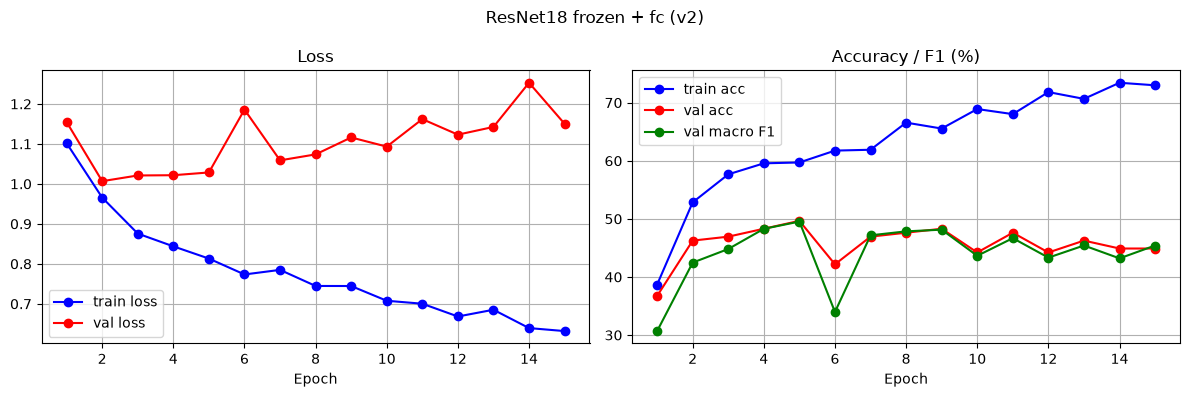

In [4]:
# ============================================================
# 05_transfer_learning_classifier_v2 - Cell 4
# FINAL TEST (frozen ResNet18 + fc): metrics, source-wise, curves, misclassified CSV
# ============================================================

# Best-val checkpoint (epoch 5) ke fc weights load karta hai
fc.load_state_dict(torch.load(BEST_PATH))

# Test pe evaluate karta hai (pehli aur akhri baar is model ke liye)
test_loss, test_acc, test_f1, test_preds, test_true = evaluate(test_loader)

# Headline numbers
print(f"Checkpoint epoch: {best_epoch}")
print(f"TEST accuracy: {test_acc:.2f}% | TEST macro F1: {test_f1:.2f}%")

# Confusion matrix (rows=true, cols=pred; order good/average/poor)
print("\nConfusion matrix (order good/average/poor):")
print(confusion_matrix(test_true, test_preds, labels=[0, 1, 2]))

# Per-class report
print("\nClassification report:")
print(classification_report(test_true, test_preds, target_names=CLASS_NAMES, digits=3))

# Purana ResNet18 result (leakage wala, sirf reference)
print("OLD ResNet18 (200 imgs, test=40, checkpoint test pe chuna gaya tha): acc 67.5% | macro F1 67.36%")

# Numpy arrays (mask ke liye)
true_arr = np.array(test_true)
pred_arr = np.array(test_preds)

# Source-wise results
print("\nSOURCE-WISE (test set):")
rows = []
for src in ["old", "b1", "b2", "b3"]:
    mask = (test_df["source"] == src).values
    rows.append({
        "Source": src,
        "n": int(mask.sum()),
        "Acc (%)": round(accuracy_score(true_arr[mask], pred_arr[mask]) * 100, 1),
        "Macro F1 (%)": round(f1_score(true_arr[mask], pred_arr[mask], average="macro") * 100, 1),
    })
print(pd.DataFrame(rows).to_string(index=False))

# Misclassified audit table
audit_df = test_df[["filename", "label", "score", "source"]].copy().reset_index(drop=True)
audit_df["pred_resnet_fc"] = [CLASS_NAMES[p] for p in test_preds]
audit_df["correct"] = audit_df["label"].values == audit_df["pred_resnet_fc"].values

# Galat predictions CSV me save
wrong_df = audit_df[~audit_df["correct"]]
WRONG_CSV = os.path.join(DATASET_DIR, "misclassified_resnet_fc_test.csv")
wrong_df.to_csv(WRONG_CSV, index=False)
print("\nWrong predictions:", len(wrong_df), "of", len(audit_df))
print("Saved:", WRONG_CSV)

# Training curves
epochs_range = range(1, EPOCHS + 1)
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, history["train_loss"], "b-o", label="train loss")
plt.plot(epochs_range, history["val_loss"], "r-o", label="val loss")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history["train_acc"], "b-o", label="train acc")
plt.plot(epochs_range, history["val_acc"], "r-o", label="val acc")
plt.plot(epochs_range, history["val_f1"], "g-o", label="val macro F1")
plt.title("Accuracy / F1 (%)")
plt.xlabel("Epoch")
plt.legend()
plt.grid(True)

plt.suptitle("ResNet18 frozen + fc (v2)")
plt.tight_layout()
plt.show()

In [5]:
# ============================================================
# 05_transfer_learning_classifier_v2 - Cell 5
# Fine-tuning ke liye: layer3 tak ke feature maps (256 x 14 x 14) cache karna (backbone frozen)
# ============================================================

# ResNet18 ka layer3 tak ka hissa (conv1 se layer3 tak), jo frozen rahega
front = nn.Sequential(
    backbone.conv1, backbone.bn1, backbone.relu, backbone.maxpool,
    backbone.layer1, backbone.layer2, backbone.layer3,
)

# Eval mode me rakhta hai (BatchNorm stats fix)
front.eval()

# Ek split ke layer3 outputs nikalne ka function
def extract_layer3(df, split_name, batch_size=32):

    # Start time
    t0 = time.time()
    files = df["filename"].tolist()
    outs = []

    # Batches me process
    for start in range(0, len(files), batch_size):
        batch = []
        for fname in files[start:start + batch_size]:
            # Image load, RGB, 224x224 resize (pehle jaisa)
            img = Image.open(os.path.join(IMAGES_DIR, fname)).convert("RGB")
            img = img.resize((224, 224), Image.BILINEAR)
            # Tensor me convert aur ImageNet normalize
            t = torch.from_numpy(np.array(img, dtype=np.uint8)).permute(2, 0, 1).float() / 255.0
            t = (t - MEAN) / STD
            batch.append(t)
        xb = torch.stack(batch)

        # Gradient ke bina layer3 tak forward pass
        with torch.no_grad():
            outs.append(front(xb))

    # Saare batches jodta hai (N, 256, 14, 14)
    outs = torch.cat(outs)
    print(f"{split_name}: {tuple(outs.shape)} in {time.time() - t0:.1f} sec")
    return outs

# Teeno splits ke layer3 outputs
train_l3 = extract_layer3(train_df, "train")
val_l3 = extract_layer3(val_df, "val")
test_l3 = extract_layer3(test_df, "test")

# Memory size print karta hai (MB me)
total_mb = sum(t.numel() * 4 for t in [train_l3, val_l3, test_l3]) / 1e6
print(f"Total cached size: {total_mb:.0f} MB")

# NaN check
print("NaN in train_l3:", bool(torch.isnan(train_l3).any()))

train: (685, 256, 14, 14) in 28.6 sec
val: (147, 256, 14, 14) in 5.2 sec
test: (147, 256, 14, 14) in 5.3 sec
Total cached size: 196 MB
NaN in train_l3: False


In [6]:
# ============================================================
# 05_transfer_learning_classifier_v2 - Cell 6
# v2b: layer4 + fc fine-tune (cached layer3 outputs pe), VAL se best checkpoint
# ============================================================

# deepcopy ke liye (pretrained layer4 ki copy banane ke liye)
import copy

# Seed fix (init repeatable)
torch.manual_seed(SEED)

# Fine-tune model: pretrained layer4 + global avg pool + dropout + naya fc head
class FineTuneHead(nn.Module):

    # Layers define karta hai
    def __init__(self):
        super().__init__()

        # Pretrained layer4 ki copy (ye trainable hogi)
        self.layer4 = copy.deepcopy(backbone.layer4)

        # layer4 ke saare parameters ko trainable banata hai (backbone me wo frozen the)
        for p in self.layer4.parameters():
            p.requires_grad = True

        # Global average pooling: (512, 7, 7) -> (512, 1, 1)
        self.pool = nn.AdaptiveAvgPool2d(1)

        # Overfitting kam karne ke liye dropout
        self.drop = nn.Dropout(0.5)

        # Naya classification head: 512 -> 3
        self.fc = nn.Linear(512, 3)

    # Forward pass: layer3 outputs input hain
    def forward(self, x):
        x = self.layer4(x)
        x = self.pool(x).flatten(1)
        x = self.drop(x)
        return self.fc(x)

# Model ka object
ft_model = FineTuneHead()

# Trainable parameters ki count print karta hai
n_train = sum(p.numel() for p in ft_model.parameters() if p.requires_grad)
print("Trainable parameters:", n_train)

# DataLoaders: layer3 outputs ke batches (batch_size=16, sirf train shuffle)
g = torch.Generator()
g.manual_seed(SEED)
ft_train_loader = DataLoader(TensorDataset(train_l3, train_labels), batch_size=16, shuffle=True, generator=g)
ft_val_loader = DataLoader(TensorDataset(val_l3, val_labels), batch_size=16, shuffle=False)
ft_test_loader = DataLoader(TensorDataset(test_l3, test_labels), batch_size=16, shuffle=False)

# Optimizer: layer4 ke liye chhota lr (1e-4), head ke liye bada (1e-3), weight decay 1e-4
ft_optimizer = optim.Adam([
    {"params": ft_model.layer4.parameters(), "lr": 1e-4},
    {"params": ft_model.fc.parameters(), "lr": 1e-3},
], weight_decay=1e-4)

# Checkpoint path
FT_BEST_PATH = os.path.join(MODEL_DIR, "resnet18_layer4_ft_v2_best.pth")

# Kisi bhi loader pe fine-tune model evaluate karne ka function
def evaluate_ft(loader):
    ft_model.eval()
    total_loss, preds_all, labels_all = 0.0, [], []
    with torch.no_grad():
        for xb, yb in loader:
            out = ft_model(xb)
            total_loss += criterion(out, yb).item() * yb.size(0)
            preds_all.extend(out.argmax(dim=1).tolist())
            labels_all.extend(yb.tolist())
    avg_loss = total_loss / len(labels_all)
    acc = accuracy_score(labels_all, preds_all) * 100
    f1 = f1_score(labels_all, preds_all, average="macro") * 100
    return avg_loss, acc, f1, preds_all, labels_all

# Training settings
FT_EPOCHS = 10
ft_history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "val_f1": []}
ft_best_f1, ft_best_epoch = -1.0, 0

print("Fine-tuning started...")
print("=" * 70)
start_time = time.time()

for epoch in range(1, FT_EPOCHS + 1):

    # Training mode (dropout on, BatchNorm layer4 me update hoga)
    ft_model.train()
    running_loss, correct, total = 0.0, 0, 0

    for xb, yb in ft_train_loader:
        out = ft_model(xb)
        loss = criterion(out, yb)
        ft_optimizer.zero_grad()
        loss.backward()
        ft_optimizer.step()
        running_loss += loss.item() * yb.size(0)
        correct += (out.argmax(dim=1) == yb).sum().item()
        total += yb.size(0)

    # Epoch ka train loss/acc
    train_loss = running_loss / total
    train_acc = correct / total * 100

    # VAL pe evaluate
    val_loss, val_acc, val_f1, _, _ = evaluate_ft(ft_val_loader)

    # History
    ft_history["train_loss"].append(train_loss)
    ft_history["train_acc"].append(train_acc)
    ft_history["val_loss"].append(val_loss)
    ft_history["val_acc"].append(val_acc)
    ft_history["val_f1"].append(val_f1)

    # Best val macro F1 pe checkpoint save
    star = ""
    if val_f1 > ft_best_f1:
        ft_best_f1, ft_best_epoch = val_f1, epoch
        torch.save(ft_model.state_dict(), FT_BEST_PATH)
        star = "  <-- best (saved)"

    print(f"Epoch [{epoch:02d}/{FT_EPOCHS}] train loss {train_loss:.3f} acc {train_acc:.1f}% | "
          f"val loss {val_loss:.3f} acc {val_acc:.1f}% F1 {val_f1:.1f}% | {time.time() - start_time:.0f}s{star}")

print("=" * 70)
print(f"Fine-tuning complete. Best val macro F1: {ft_best_f1:.2f}% at epoch {ft_best_epoch}")
print("Checkpoint:", FT_BEST_PATH)

Trainable parameters: 8395267
Fine-tuning started...
Epoch [01/10] train loss 1.144 acc 43.1% | val loss 0.986 acc 51.0% F1 50.3% | 7s  <-- best (saved)
Epoch [02/10] train loss 0.565 acc 75.3% | val loss 0.991 acc 56.5% F1 56.8% | 13s  <-- best (saved)
Epoch [03/10] train loss 0.303 acc 89.3% | val loss 1.087 acc 55.1% F1 55.5% | 19s
Epoch [04/10] train loss 0.141 acc 95.8% | val loss 1.225 acc 56.5% F1 56.3% | 26s
Epoch [05/10] train loss 0.064 acc 98.4% | val loss 1.390 acc 55.1% F1 55.4% | 33s
Epoch [06/10] train loss 0.067 acc 97.8% | val loss 1.406 acc 57.1% F1 57.5% | 40s  <-- best (saved)
Epoch [07/10] train loss 0.037 acc 99.3% | val loss 1.574 acc 55.1% F1 55.3% | 47s
Epoch [08/10] train loss 0.026 acc 99.6% | val loss 1.567 acc 57.1% F1 57.3% | 54s
Epoch [09/10] train loss 0.039 acc 98.7% | val loss 1.586 acc 55.1% F1 54.6% | 63s
Epoch [10/10] train loss 0.020 acc 99.4% | val loss 1.809 acc 51.7% F1 51.6% | 71s
Fine-tuning complete. Best val macro F1: 57.46% at epoch 6
Check

Checkpoint epoch: 6
TEST accuracy: 53.06% | TEST macro F1: 53.20%

Confusion matrix (order good/average/poor):
[[30 12  6]
 [19 23 17]
 [ 7  8 25]]

Classification report:
              precision    recall  f1-score   support

        good      0.536     0.625     0.577        48
     average      0.535     0.390     0.451        59
        poor      0.521     0.625     0.568        40

    accuracy                          0.531       147
   macro avg      0.530     0.547     0.532       147
weighted avg      0.531     0.531     0.524       147

SOURCE-WISE (test set):
Source  n  Acc (%)  Macro F1 (%)
   old 30     50.0          51.1
    b1 19     52.6          51.6
    b2 42     47.6          47.6
    b3 56     58.9          58.1

Wrong predictions: 69 of 147
Saved: C:\Projects\Internship_Learning\dataset_final\misclassified_resnet_ft_test.csv

Top 10 most confident wrong predictions:
    filename   label  score source pred_ft  confidence  correct
 b3_0419.png average    6.0     b3  

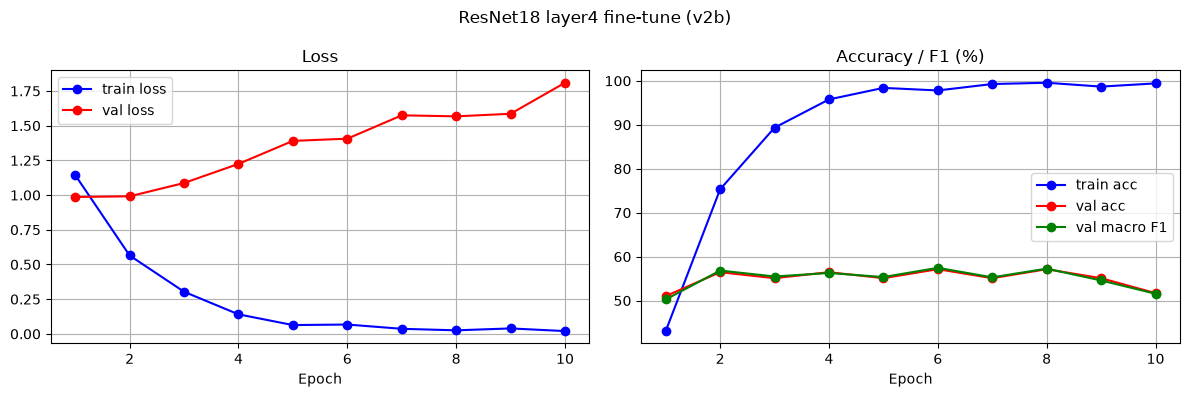

In [7]:
# ============================================================
# 05_transfer_learning_classifier_v2 - Cell 7
# FINAL TEST (layer4 fine-tuned): metrics, source-wise, confidence, misclassified CSV, curves, summary
# ============================================================

# Best-val checkpoint (epoch 6) load karta hai
ft_model.load_state_dict(torch.load(FT_BEST_PATH))

# Test pe evaluate (is model ke liye pehli aur akhri baar)
ft_test_loss, ft_test_acc, ft_test_f1, ft_preds, ft_true = evaluate_ft(ft_test_loader)

# Headline numbers
print(f"Checkpoint epoch: {ft_best_epoch}")
print(f"TEST accuracy: {ft_test_acc:.2f}% | TEST macro F1: {ft_test_f1:.2f}%")

# Confusion matrix (rows=true, cols=pred; order good/average/poor)
print("\nConfusion matrix (order good/average/poor):")
print(confusion_matrix(ft_true, ft_preds, labels=[0, 1, 2]))

# Per-class report
print("\nClassification report:")
print(classification_report(ft_true, ft_preds, target_names=CLASS_NAMES, digits=3))

# Numpy arrays (mask ke liye)
true_arr = np.array(ft_true)
pred_arr = np.array(ft_preds)

# Source-wise results
print("SOURCE-WISE (test set):")
rows = []
for src in ["old", "b1", "b2", "b3"]:
    mask = (test_df["source"] == src).values
    rows.append({
        "Source": src,
        "n": int(mask.sum()),
        "Acc (%)": round(accuracy_score(true_arr[mask], pred_arr[mask]) * 100, 1),
        "Macro F1 (%)": round(f1_score(true_arr[mask], pred_arr[mask], average="macro") * 100, 1),
    })
print(pd.DataFrame(rows).to_string(index=False))

# Softmax probabilities nikalta hai (model ki confidence ke liye)
ft_model.eval()
probs_all = []
with torch.no_grad():
    for xb, yb in ft_test_loader:
        probs_all.append(torch.softmax(ft_model(xb), dim=1))
probs_all = torch.cat(probs_all).numpy()

# Audit table: filename, true label, score, source, prediction, confidence, correct
audit_df = test_df[["filename", "label", "score", "source"]].copy().reset_index(drop=True)
audit_df["pred_ft"] = [CLASS_NAMES[p] for p in ft_preds]
audit_df["confidence"] = np.round(probs_all.max(axis=1), 3)
audit_df["correct"] = audit_df["label"].values == audit_df["pred_ft"].values

# Galat predictions ko confidence ke hisaab se sort karke save karta hai (sabse confident galti sabse upar)
wrong_df = audit_df[~audit_df["correct"]].sort_values("confidence", ascending=False)
WRONG_CSV = os.path.join(DATASET_DIR, "misclassified_resnet_ft_test.csv")
wrong_df.to_csv(WRONG_CSV, index=False)
print("\nWrong predictions:", len(wrong_df), "of", len(audit_df))
print("Saved:", WRONG_CSV)
print("\nTop 10 most confident wrong predictions:")
print(wrong_df.head(10).to_string(index=False))

# Sabhi models ka final test summary (pehle ke results Cell 4 / 03 / 04 se)
summary = pd.DataFrame([
    {"Model": "Random Forest (22 feat)", "Test Acc (%)": 36.05, "Test Macro F1 (%)": 35.97},
    {"Model": "CNN from scratch", "Test Acc (%)": 38.10, "Test Macro F1 (%)": 37.72},
    {"Model": "SVM (22 feat)", "Test Acc (%)": 40.14, "Test Macro F1 (%)": 39.80},
    {"Model": "Logistic Regression (22 feat)", "Test Acc (%)": 45.58, "Test Macro F1 (%)": 45.22},
    {"Model": "ResNet18 frozen + fc", "Test Acc (%)": 52.38, "Test Macro F1 (%)": 52.65},
    {"Model": "ResNet18 layer4 fine-tuned", "Test Acc (%)": round(ft_test_acc, 2), "Test Macro F1 (%)": round(ft_test_f1, 2)},
])
print("\nFINAL SUMMARY (test set, n=147):")
print(summary.to_string(index=False))

# Training curves
epochs_range = range(1, FT_EPOCHS + 1)
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, ft_history["train_loss"], "b-o", label="train loss")
plt.plot(epochs_range, ft_history["val_loss"], "r-o", label="val loss")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, ft_history["train_acc"], "b-o", label="train acc")
plt.plot(epochs_range, ft_history["val_acc"], "r-o", label="val acc")
plt.plot(epochs_range, ft_history["val_f1"], "g-o", label="val macro F1")
plt.title("Accuracy / F1 (%)")
plt.xlabel("Epoch")
plt.legend()
plt.grid(True)

plt.suptitle("ResNet18 layer4 fine-tune (v2b)")
plt.tight_layout()
plt.show()

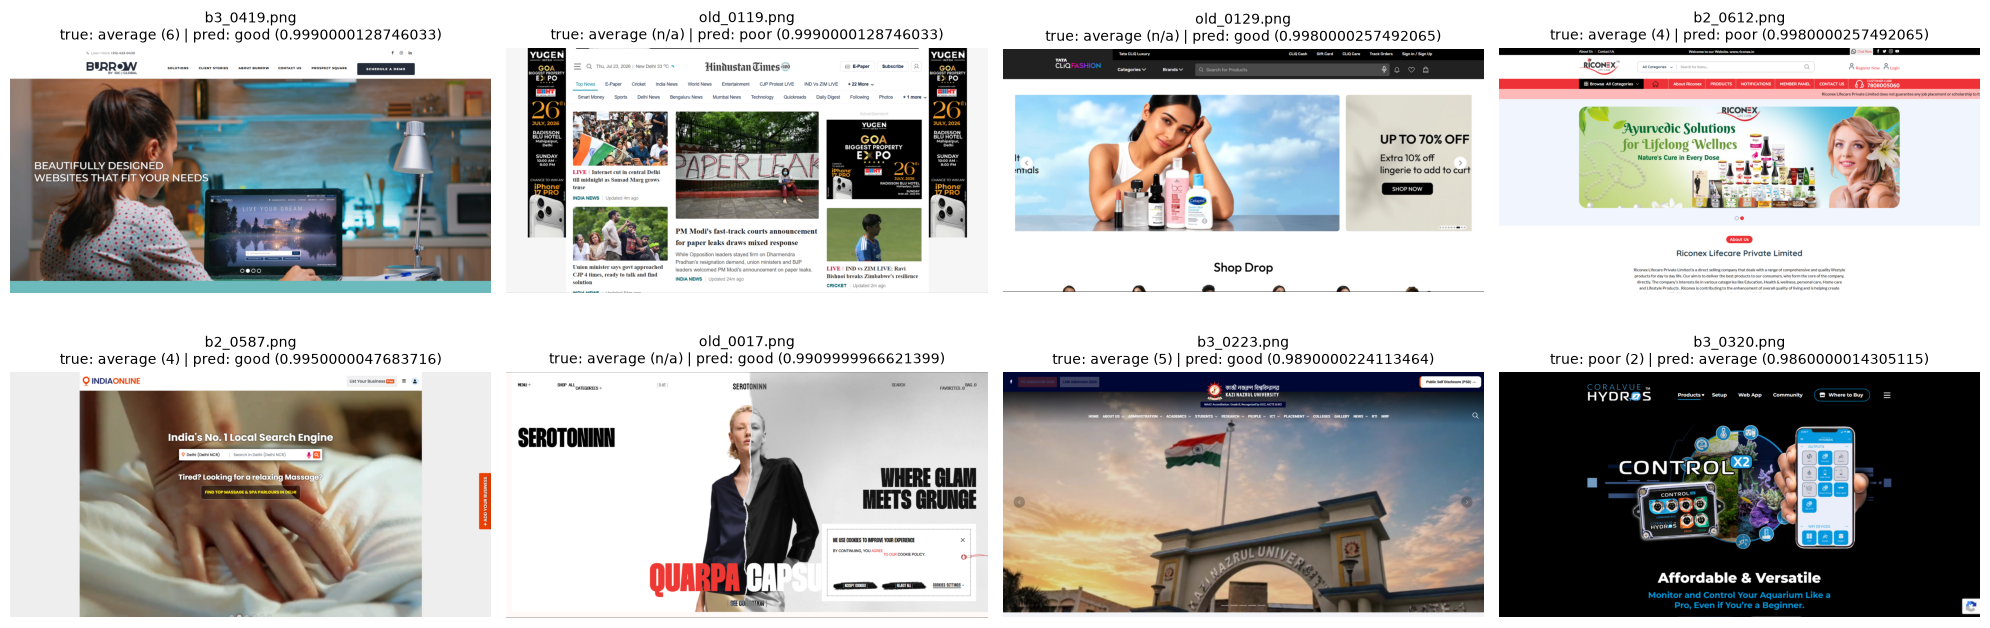

In [8]:
# ============================================================
# 05_transfer_learning_classifier_v2 - Cell 8
# Sabse confident 8 galat predictions ki images dekhna (audit)
# ============================================================

# Sabse confident 8 galat rows (wrong_df confidence ke hisaab se sorted hai)
top_wrong = wrong_df.head(8)

# 2 rows x 4 columns ka grid banata hai
fig, axes = plt.subplots(2, 4, figsize=(20, 7))

# Har galat prediction ke liye image dikhata hai
for ax, (_, row) in zip(axes.flatten(), top_wrong.iterrows()):

    # Original (bina resize) image load karta hai
    img = Image.open(os.path.join(IMAGES_DIR, row["filename"])).convert("RGB")

    # Image dikhata hai
    ax.imshow(img)
    ax.axis("off")

    # Title: filename, true label (score), prediction aur confidence
    score_txt = "n/a" if pd.isna(row["score"]) else int(row["score"])
    ax.set_title(f"{row['filename']}\ntrue: {row['label']} ({score_txt}) | pred: {row['pred_ft']} ({row['confidence']})", fontsize=10)

plt.tight_layout()
plt.show()